In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv(r"C:\Users\symbi\Downloads\ai4i+2020+predictive+maintenance+dataset\ai4i2020.csv")

data.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
data.shape

(10000, 14)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [6]:
data.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [7]:
data.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [8]:
data.duplicated().sum()

np.int64(0)

In [9]:
data["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [10]:
data["Machine failure"].value_counts(normalize=True) * 100

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

In [11]:
data["Type"].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [12]:
data.groupby("Type")["Machine failure"].agg(["count", "sum", "mean"])

,count,sum,mean
Type,,,
H,1003,21,0.020937
L,6000,235,0.039167
M,2997,83,0.027694


# Predictive Maintenance & Machine Failure Intelligence System

## Project Objective

The objective of this project is to develop a machine learning-based predictive maintenance system capable of identifying machines at risk of failure using operational and sensor-related data.

The project analyzes machine conditions such as temperature, rotational speed, torque, tool wear, and product type to identify patterns associated with machine failure.

The final system will predict machine failure risk and provide interpretable insights that can support preventive maintenance decisions and reduce unexpected equipment downtime.

## Dataset

The project uses the AI4I 2020 Predictive Maintenance Dataset containing 10,000 machine observations and operational characteristics.

## Target Variable

**Machine failure**

- 0 → No Machine Failure
- 1 → Machine Failure

## Data Cleaning & Validation

In [13]:
Cleaned_data = data.copy()

In [14]:
Cleaned_data.drop(columns=["UDI", "Product ID"], inplace=True)

In [15]:
Cleaned_data["Type"].unique()

array(['M', 'L', 'H'], dtype=object)

In [16]:
Cleaned_data["Type"].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [17]:
binary_columns = ["Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"]

for column in binary_columns:
    print(column, Cleaned_data[column].unique())

Machine failure [0 1]
TWF [0 1]
HDF [0 1]
PWF [0 1]
OSF [0 1]
RNF [0 1]


In [18]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

Cleaned_data[failure_modes].sum().sort_values(ascending=False)

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64

In [19]:
pd.crosstab(
    Cleaned_data["Machine failure"],
    Cleaned_data[failure_modes].sum(axis=1),
    margins=True
)

col_0,0,1,2,3,All
Machine failure,,,,,
0,9643,18,0,0,9661
1,9,306,23,1,339
All,9652,324,23,1,10000


In [20]:
Cleaned_data["Failure_Mode_Count"] = Cleaned_data[failure_modes].sum(axis=1)

Cleaned_data.groupby("Machine failure")["Failure_Mode_Count"].value_counts()

Machine failure  Failure_Mode_Count
0                0                     9643
                 1                       18
1                1                      306
                 2                       23
                 0                        9
                 3                        1
Name: count, dtype: int64

In [21]:
sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for column in sensor_columns:
    print(f"\n{column}")
    print("Minimum:", Cleaned_data[column].min())
    print("Maximum:", Cleaned_data[column].max())


Air temperature [K]
Minimum: 295.3
Maximum: 304.5

Process temperature [K]
Minimum: 305.7
Maximum: 313.8

Rotational speed [rpm]
Minimum: 1168
Maximum: 2886

Torque [Nm]
Minimum: 3.8
Maximum: 76.6

Tool wear [min]
Minimum: 0
Maximum: 253


In [22]:
print("Dataset Shape:", Cleaned_data.shape)
print("Missing Values:", Cleaned_data.isnull().sum().sum())
print("Duplicates:", Cleaned_data.duplicated().sum())

Dataset Shape: (10000, 13)
Missing Values: 0
Duplicates: 0


## Exploratory Data Analysis

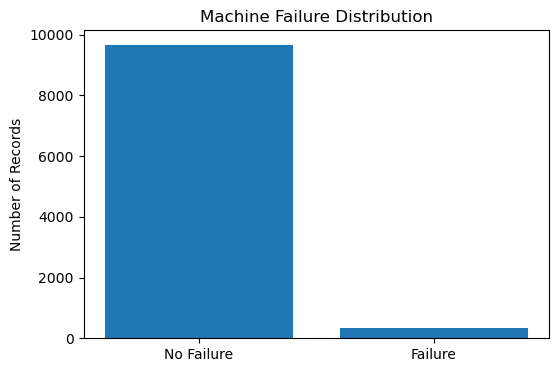

In [23]:
failure_counts = Cleaned_data["Machine failure"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(["No Failure", "Failure"], failure_counts.values)

plt.title("Machine Failure Distribution")
plt.ylabel("Number of Records")

plt.show()

### Observation

The target variable is highly imbalanced. Most machine observations represent normal operating conditions, while only 339 out of 10,000 records correspond to machine failures.

Because of this imbalance, accuracy alone will not be sufficient for evaluating machine learning models. Metrics such as recall, precision, F1-score, confusion matrix, and ROC-AUC will also be considered.

### Failure vs No Failure

In [24]:
Cleaned_data.groupby("Machine failure")[sensor_columns].mean().T

Machine failure,0,1
Air temperature [K],299.973999,300.886431
Process temperature [K],309.995570,310.290265
Rotational speed [rpm],1540.260014,1496.486726
Torque [Nm],39.629655,50.168142
Tool wear [min],106.693717,143.781711


### Failure rate by machine type

In [25]:
type_failure = (
    Cleaned_data.groupby("Type")["Machine failure"]
    .mean()
    .sort_values(ascending=False) * 100
)

type_failure

Type
L    3.916667
M    2.769436
H    2.093719
Name: Machine failure, dtype: float64

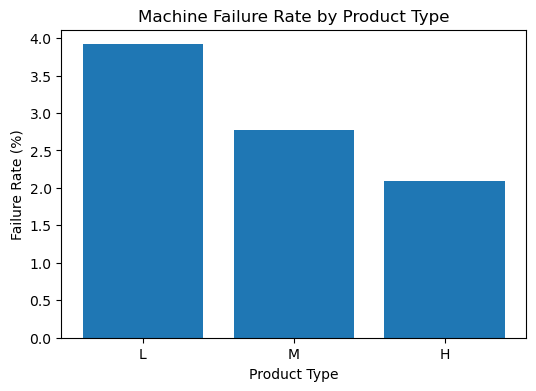

In [26]:
plt.figure(figsize=(6, 4))

plt.bar(type_failure.index, type_failure.values)

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")

plt.show()

### Tool wear vs machine failure

In [28]:
Cleaned_data.groupby("Machine failure")["Tool wear [min]"].describe()

,count,mean,std,min,25%,50%,75%,max
Machine failure,,,,,,,,
0,9661.0,106.693717,62.945790,0.0,52.0,107.0,160.0,246.0
1,339.0,143.781711,72.759876,0.0,84.5,165.0,207.5,253.0


<Figure size 700x400 with 0 Axes>

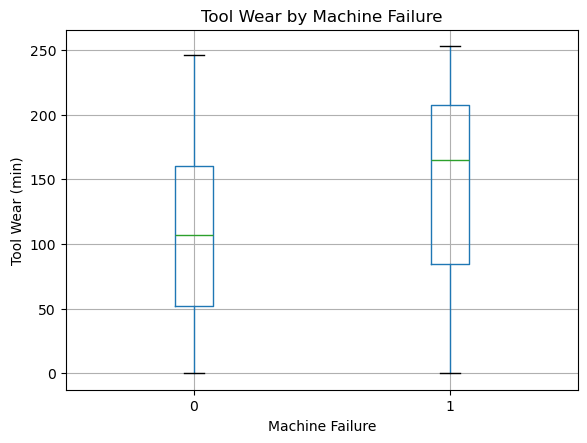

In [29]:
plt.figure(figsize=(7, 4))

Cleaned_data.boxplot(
    column="Tool wear [min]",
    by="Machine failure"
)

plt.title("Tool Wear by Machine Failure")
plt.suptitle("")
plt.xlabel("Machine Failure")
plt.ylabel("Tool Wear (min)")

plt.show()

### Torque vs machine failure

In [30]:
Cleaned_data.groupby("Machine failure")["Torque [Nm]"].describe()

,count,mean,std,min,25%,50%,75%,max
Machine failure,,,,,,,,
0,9661.0,39.629655,9.472080,12.6,33.10,39.9,46.3,70.0
1,339.0,50.168142,16.374498,3.8,45.95,53.7,61.2,76.6


<Figure size 700x400 with 0 Axes>

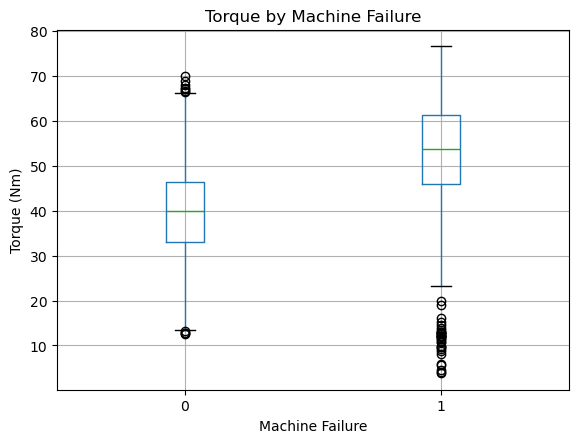

In [31]:
plt.figure(figsize=(7, 4))

Cleaned_data.boxplot(
    column="Torque [Nm]",
    by="Machine failure"
)

plt.title("Torque by Machine Failure")
plt.suptitle("")
plt.xlabel("Machine Failure")
plt.ylabel("Torque (Nm)")

plt.show()

### Rotational speed vs failure

In [32]:
Cleaned_data.groupby("Machine failure")["Rotational speed [rpm]"].describe()

,count,mean,std,min,25%,50%,75%,max
Machine failure,,,,,,,,
0,9661.0,1540.260014,167.394734,1168.0,1429.0,1507.0,1615.0,2695.0
1,339.0,1496.486726,384.943547,1181.0,1326.5,1365.0,1421.5,2886.0


<Figure size 700x400 with 0 Axes>

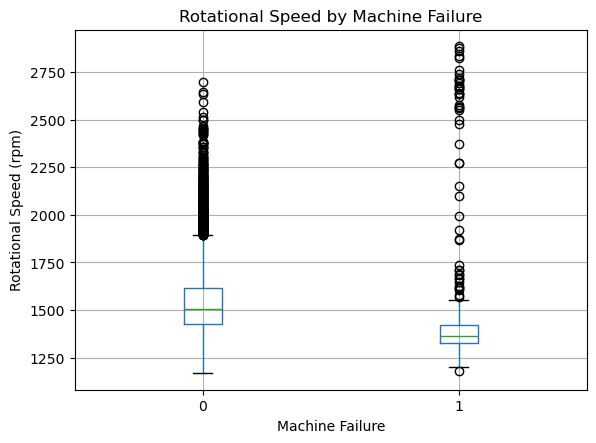

In [33]:
plt.figure(figsize=(7, 4))

Cleaned_data.boxplot(
    column="Rotational speed [rpm]",
    by="Machine failure"
)

plt.title("Rotational Speed by Machine Failure")
plt.suptitle("")
plt.xlabel("Machine Failure")
plt.ylabel("Rotational Speed (rpm)")

plt.show()

### Failure-mode distribution

In [34]:
Cleaned_data[failure_modes].sum().sort_values(ascending=False)

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64

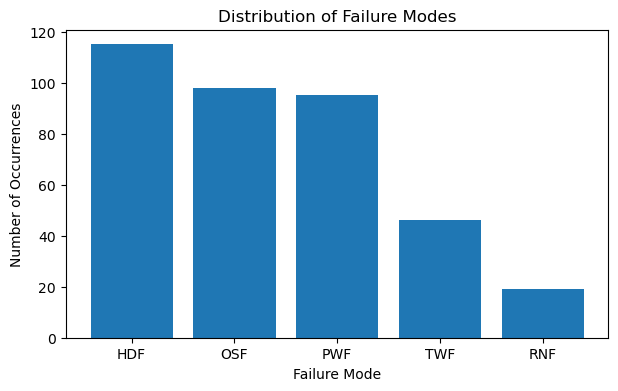

In [35]:
failure_mode_counts = Cleaned_data[failure_modes].sum().sort_values(ascending=False)

plt.figure(figsize=(7, 4))

plt.bar(failure_mode_counts.index, failure_mode_counts.values)

plt.title("Distribution of Failure Modes")
plt.xlabel("Failure Mode")
plt.ylabel("Number of Occurrences")

plt.show()

## Feature Engineering

In [36]:
Feature_data = Cleaned_data.copy()

### Temperature Difference

In [37]:
Feature_data["Temperature_Difference"] = (
    Feature_data["Process temperature [K]"] -
    Feature_data["Air temperature [K]"]
)

In [38]:
Feature_data.groupby("Machine failure")["Temperature_Difference"].describe()

,count,mean,std,min,25%,50%,75%,max
Machine failure,,,,,,,,
0,9661.0,10.021571,0.988422,7.6,9.3,9.8,11.0,12.1
1,339.0,9.403835,1.164445,7.6,8.4,9.3,10.5,12.0


### Mechanical Power Proxy

In [39]:
Feature_data["Power_W"] = (
    Feature_data["Torque [Nm]"] *
    Feature_data["Rotational speed [rpm]"] *
    2 * np.pi / 60
)

In [40]:
Feature_data.groupby("Machine failure")["Power_W"].describe()

,count,mean,std,min,25%,50%,75%,max
Machine failure,,,,,,,,
0,9661.0,6244.547534,1011.394393,3515.033772,5549.309263,6243.046225,6952.051327,8998.024015
1,339.0,7282.819485,1851.137977,1148.440610,6669.056661,7611.429737,8548.854805,10469.923005


### Tool Wear × Torque interaction

In [41]:
Feature_data["Wear_Torque_Interaction"] = (
    Feature_data["Tool wear [min]"] *
    Feature_data["Torque [Nm]"]
)

In [42]:
Feature_data.groupby("Machine failure")["Wear_Torque_Interaction"].describe()

,count,mean,std,min,25%,50%,75%,max
Machine failure,,,,,,,,
0,9661.0,4213.842708,2709.744211,0.0,1943.40,3952.8,6175.2,11919.8
1,339.0,7187.938348,4234.039961,0.0,3508.05,7681.8,11146.8,16497.0


In [43]:
engineered_features = [
    "Temperature_Difference",
    "Power_W",
    "Wear_Torque_Interaction"
]

Feature_data.groupby("Machine failure")[engineered_features].mean().T

Machine failure,0,1
Temperature_Difference,10.021571,9.403835
Power_W,6244.547534,7282.819485
Wear_Torque_Interaction,4213.842708,7187.938348


In [44]:
model_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature_Difference",
    "Power_W",
    "Wear_Torque_Interaction",
    "Machine failure"
]

correlation = Feature_data[model_features].corr()

correlation["Machine failure"].sort_values(ascending=False)

Machine failure            1.000000
Torque [Nm]                0.191321
Wear_Torque_Interaction    0.190427
Power_W                    0.176039
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Process temperature [K]    0.035946
Rotational speed [rpm]    -0.044188
Temperature_Difference    -0.111676
Name: Machine failure, dtype: float64

## Prepare the Data for ML

In [45]:
y = Feature_data["Machine failure"]

In [46]:
x = Feature_data[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
        "Temperature_Difference",
        "Power_W",
        "Wear_Torque_Interaction"
    ]
].copy()

In [48]:
x.shape, y.shape

((10000, 9), (10000,))

In [49]:
x = pd.get_dummies(x, columns=["Type"], drop_first=True, dtype=int)

In [50]:
x.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature_Difference,Power_W,Wear_Torque_Interaction,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,10.5,6951.590560,0.0,0,1
1,298.2,308.7,1408,46.3,3,10.5,6826.722724,138.9,1,0
2,298.1,308.5,1498,49.4,5,10.4,7749.387543,247.0,1,0
3,298.2,308.6,1433,39.5,7,10.4,5927.504659,276.5,1,0
4,298.2,308.7,1408,40.0,9,10.5,5897.816608,360.0,1,0


In [52]:
x.columns

Index(['Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]',
       'Temperature_Difference', 'Power_W', 'Wear_Torque_Interaction',
       'Type_L', 'Type_M'],
      dtype='object')

In [53]:
from sklearn.model_selection import train_test_split

In [54]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [55]:
print("X Train:", x_train.shape)
print("X Test:", x_test.shape)

print("\nTraining Target:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

X Train: (8000, 10)
X Test: (2000, 10)

Training Target:
Machine failure
0    7729
1     271
Name: count, dtype: int64
Machine failure
0    96.6125
1     3.3875
Name: proportion, dtype: float64

Testing Target:
Machine failure
0    1932
1      68
Name: count, dtype: int64
Machine failure
0    96.6
1     3.4
Name: proportion, dtype: float64


## Baseline Model

In [56]:
from sklearn.preprocessing import StandardScaler

In [57]:
scaler = StandardScaler()

In [58]:
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [59]:
from sklearn.linear_model import LogisticRegression

In [60]:
lr_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

lr_model.fit(x_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [61]:
lr_pred = lr_model.predict(x_test_scaled)

In [62]:
lr_prob = lr_model.predict_proba(x_test_scaled)[:, 1]

In [63]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [64]:
print("Accuracy :", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall   :", recall_score(y_test, lr_pred))
print("F1 Score :", f1_score(y_test, lr_pred))
print("ROC-AUC  :", roc_auc_score(y_test, lr_prob))

Accuracy : 0.9675
Precision: 0.5714285714285714
Recall   : 0.17647058823529413
F1 Score : 0.2696629213483146
ROC-AUC  : 0.9254810619900135


### Baseline Logistic Regression Observation

The baseline Logistic Regression model achieved 96.75% accuracy and a ROC-AUC score of 0.9255. However, failure-class recall was only 17.65%, indicating that the model failed to identify most actual machine failures.

The high accuracy is influenced by the highly imbalanced target distribution, where only 3.39% of observations represent machine failures.

Therefore, accuracy alone is not an appropriate metric for this predictive maintenance problem. Greater emphasis should be placed on recall, precision, F1-score, and the model's ability to identify actual machine failures.

## Handle Class Imbalance

### Balanced Logistic Regression

In [65]:
lr_balanced = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

lr_balanced.fit(x_train_scaled, y_train)

lr_balanced_pred = lr_balanced.predict(x_test_scaled)
lr_balanced_prob = lr_balanced.predict_proba(x_test_scaled)[:, 1]

In [66]:
print("Accuracy :", accuracy_score(y_test, lr_balanced_pred))
print("Precision:", precision_score(y_test, lr_balanced_pred))
print("Recall   :", recall_score(y_test, lr_balanced_pred))
print("F1 Score :", f1_score(y_test, lr_balanced_pred))
print("ROC-AUC  :", roc_auc_score(y_test, lr_balanced_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_balanced_pred))

Accuracy : 0.859
Precision: 0.17964071856287425
Recall   : 0.8823529411764706
F1 Score : 0.29850746268656714
ROC-AUC  : 0.9384438558031908

Confusion Matrix:
[[1658  274]
 [   8   60]]


### Random Forest

In [67]:
from sklearn.ensemble import RandomForestClassifier

In [68]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(x_train, y_train)

rf_pred = rf_model.predict(x_test)
rf_prob = rf_model.predict_proba(x_test)[:, 1]

In [69]:
print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall   :", recall_score(y_test, rf_pred))
print("F1 Score :", f1_score(y_test, rf_pred))
print("ROC-AUC  :", roc_auc_score(y_test, rf_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Accuracy : 0.9925
Precision: 0.9649122807017544
Recall   : 0.8088235294117647
F1 Score : 0.88
ROC-AUC  : 0.9817698818657898

Confusion Matrix:
[[1930    2]
 [  13   55]]


### Balanced Random Forest approach

In [70]:
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

rf_balanced.fit(x_train, y_train)

rf_balanced_pred = rf_balanced.predict(x_test)
rf_balanced_prob = rf_balanced.predict_proba(x_test)[:, 1]

In [71]:
print("Accuracy :", accuracy_score(y_test, rf_balanced_pred))
print("Precision:", precision_score(y_test, rf_balanced_pred))
print("Recall   :", recall_score(y_test, rf_balanced_pred))
print("F1 Score :", f1_score(y_test, rf_balanced_pred))
print("ROC-AUC  :", roc_auc_score(y_test, rf_balanced_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_balanced_pred))

Accuracy : 0.991
Precision: 0.9629629629629629
Recall   : 0.7647058823529411
F1 Score : 0.8524590163934426
ROC-AUC  : 0.974264705882353

Confusion Matrix:
[[1930    2]
 [  16   52]]


### Gradient Boosting

In [72]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(x_train, y_train)

gb_pred = gb_model.predict(x_test)
gb_prob = gb_model.predict_proba(x_test)[:, 1]

In [73]:
print("Accuracy :", accuracy_score(y_test, gb_pred))
print("Precision:", precision_score(y_test, gb_pred))
print("Recall   :", recall_score(y_test, gb_pred))
print("F1 Score :", f1_score(y_test, gb_pred))
print("ROC-AUC  :", roc_auc_score(y_test, gb_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gb_pred))

Accuracy : 0.993
Precision: 1.0
Recall   : 0.7941176470588235
F1 Score : 0.8852459016393442
ROC-AUC  : 0.9686814943368653

Confusion Matrix:
[[1932    0]
 [  14   54]]


In [74]:
from sklearn.metrics import average_precision_score

In [75]:
print(
    "Random Forest PR-AUC:",
    average_precision_score(y_test, rf_prob)
)

print(
    "Gradient Boosting PR-AUC:",
    average_precision_score(y_test, gb_prob)
)

Random Forest PR-AUC: 0.8937882042670193
Gradient Boosting PR-AUC: 0.900749365803163


## Cross-Validation

In [76]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [77]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

### Cross-validation — Random Forest

In [78]:
rf_cv = cross_validate(
    rf_model,
    x_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    print(
        metric,
        ":",
        round(rf_cv[f"test_{metric}"].mean(), 4),
        "+/-",
        round(rf_cv[f"test_{metric}"].std(), 4)
    )

accuracy : 0.9934 +/- 0.0016
precision : 0.978 +/- 0.0141
recall : 0.8229 +/- 0.0447
f1 : 0.8932 +/- 0.0283
roc_auc : 0.9763 +/- 0.013
average_precision : 0.8988 +/- 0.0224


### Cross-validation — Gradient Boostingm

In [79]:
gb_cv = cross_validate(
    gb_model,
    x_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    print(
        metric,
        ":",
        round(gb_cv[f"test_{metric}"].mean(), 4),
        "+/-",
        round(gb_cv[f"test_{metric}"].std(), 4)
    )

accuracy : 0.9932 +/- 0.0014
precision : 0.974 +/- 0.0251
recall : 0.823 +/- 0.0271
f1 : 0.8919 +/- 0.0226
roc_auc : 0.9819 +/- 0.015
average_precision : 0.9096 +/- 0.0212


## Feature Importance

In [80]:
rf_importance = pd.DataFrame({
    "Feature": x.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

rf_importance

,Feature,Importance
6,Power_W,0.215346
7,Wear_Torque_Interaction,0.215306
2,Rotational speed [rpm],0.165991
3,Torque [Nm],0.128057
5,Temperature_Difference,0.115621
4,Tool wear [min],0.056086
0,Air temperature [K],0.037699
1,Process temperature [K],0.032766
8,Type_L,0.022734
9,Type_M,0.010393


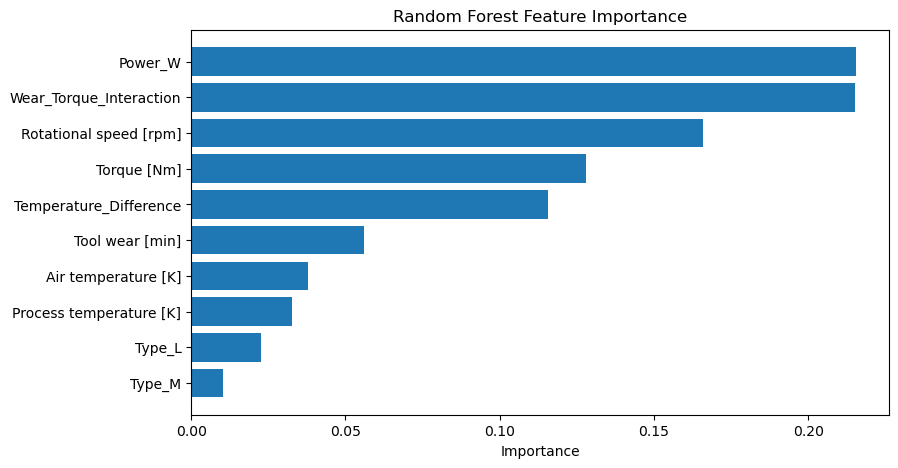

In [81]:
plt.figure(figsize=(9, 5))

plt.barh(
    rf_importance["Feature"],
    rf_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")

plt.show()

In [82]:
gb_importance = pd.DataFrame({
    "Feature": x.columns,
    "Importance": gb_model.feature_importances_
}).sort_values("Importance", ascending=False)

gb_importance

,Feature,Importance
6,Power_W,0.274476
5,Temperature_Difference,0.265547
7,Wear_Torque_Interaction,0.251382
2,Rotational speed [rpm],0.109446
4,Tool wear [min],0.040398
8,Type_L,0.030718
3,Torque [Nm],0.011217
1,Process temperature [K],0.009028
0,Air temperature [K],0.005179
9,Type_M,0.002610


In [84]:
failure_probability = rf_model.predict_proba(x_test)[:, 1]

In [86]:
results = x_test.copy()

results["Actual_Failure"] = y_test.values
results["Predicted_Failure"] = rf_pred
results["Failure_Probability"] = failure_probability

In [87]:
results.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature_Difference,Power_W,Wear_Torque_Interaction,Type_L,Type_M,Actual_Failure,Predicted_Failure,Failure_Probability
2997,300.5,309.8,1345,62.7,153,9.3,8831.174029,9593.1,1,0,0,0,0.020
4871,303.7,312.4,1513,40.1,135,8.7,6353.483679,5413.5,1,0,0,0,0.000
3858,302.5,311.4,1559,37.6,209,8.9,6138.504494,7858.4,1,0,0,0,0.055
951,295.6,306.3,1509,35.8,60,10.7,5657.191555,2148.0,0,0,0,0,0.000
6463,300.5,310.0,1358,60.4,102,9.5,8589.449418,6160.8,0,0,0,0,0.000


In [88]:
def risk_level(probability):
    if probability < 0.30:
        return "Low"
    elif probability < 0.60:
        return "Medium"
    else:
        return "High"

In [89]:
results["Risk_Level"] = results["Failure_Probability"].apply(risk_level)

In [90]:
results[
    [
        "Failure_Probability",
        "Risk_Level",
        "Predicted_Failure",
        "Actual_Failure"
    ]
].head(20)

,Failure_Probability,Risk_Level,Predicted_Failure,Actual_Failure
2997,0.020,Low,0,0
4871,0.000,Low,0,0
3858,0.055,Low,0,0
951,0.000,Low,0,0
6463,0.000,Low,0,0
3264,0.010,Low,0,0
4508,0.020,Low,0,0
2100,0.005,Low,0,0
7885,0.000,Low,0,0
2421,0.000,Low,0,0


In [91]:
results["Risk_Level"].value_counts()

Risk_Level
Low       1935
High        54
Medium      11
Name: count, dtype: int64

In [92]:
results.sort_values(
    "Failure_Probability",
    ascending=False
)[
    [
        "Torque [Nm]",
        "Tool wear [min]",
        "Rotational speed [rpm]",
        "Power_W",
        "Wear_Torque_Interaction",
        "Failure_Probability",
        "Risk_Level",
        "Actual_Failure"
    ]
].head(10)

,Torque [Nm],Tool wear [min],Rotational speed [rpm],Power_W,Wear_Torque_Interaction,Failure_Probability,Risk_Level,Actual_Failure
1391,8.8,142,2737,2522.238134,1249.6,0.985,High,1
4755,51.3,51,1295,6956.899852,2616.3,0.980,High,1
7997,9.7,143,2710,2752.768203,1387.1,0.980,High,1
7011,12.2,17,2633,3363.870806,207.4,0.970,High,1
4342,68.2,111,1284,9170.183292,7570.2,0.970,High,1
9664,54.8,231,1317,7557.792279,12658.8,0.965,High,1
8582,72.0,151,1334,10058.123040,10872.0,0.965,High,1
4565,55.0,25,1275,7343.472828,1375.0,0.960,High,1
249,56.2,218,1405,8268.776584,12251.6,0.955,High,1
8245,68.6,111,1303,9360.459087,7614.6,0.955,High,1


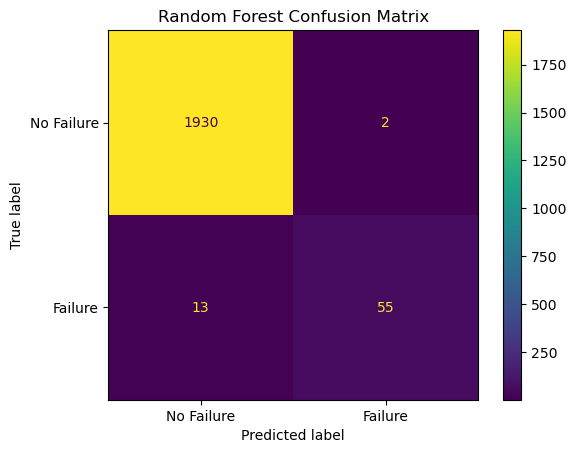

In [93]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["No Failure", "Failure"]
)

plt.title("Random Forest Confusion Matrix")
plt.show()

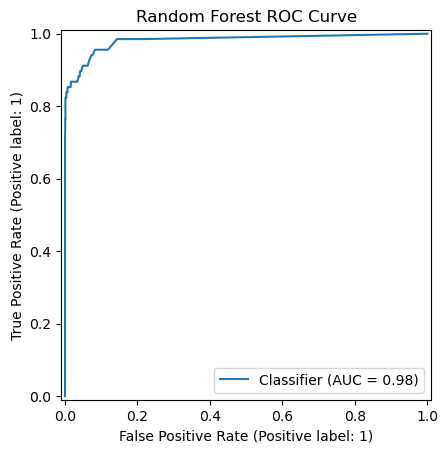

In [94]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    rf_prob
)

plt.title("Random Forest ROC Curve")
plt.show()

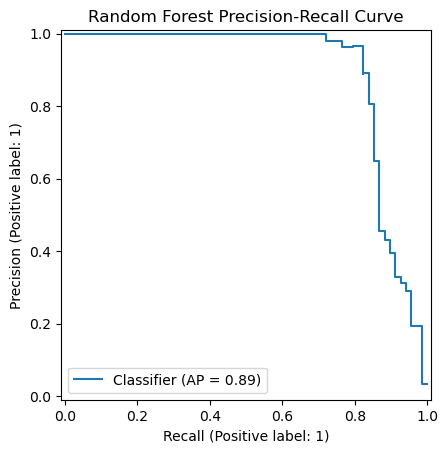

In [95]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    rf_prob
)

plt.title("Random Forest Precision-Recall Curve")
plt.show()

In [96]:
import pickle

In [97]:
with open("predictive_maintenance_model.pkl", "wb") as file:
    pickle.dump(rf_model, file)

In [98]:
results["Risk_Level"].value_counts()

Risk_Level
Low       1935
High        54
Medium      11
Name: count, dtype: int64

In [99]:
import os

os.path.exists("predictive_maintenance_model.pkl")

True

In [100]:
print(x.columns.tolist())

['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature_Difference', 'Power_W', 'Wear_Torque_Interaction', 'Type_L', 'Type_M']
